In [2]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [3]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")


In [4]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [5]:
df = df.drop(columns=["customerID"])
X = df.drop(columns=["Churn"])
y = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [6]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("Target distribution:")
print(y.value_counts())


Features shape: (7043, 19)
Target shape: (7043,)
Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [9]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns


In [10]:
print("Numerical columns:")
print(list(num_cols))

print("\nCategorical columns:")
print(list(cat_cols))


Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [12]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [13]:
from sklearn.linear_model import LogisticRegression

In [14]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [15]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

In [17]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [18]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_prob)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("ROC-AUC:", round(roc_auc, 4))

Model Evaluation Results
------------------------
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
ROC-AUC: 0.8419


In [19]:
import joblib

In [20]:
# Save the complete trained pipeline

joblib.dump(model, "../models/churn_pipeline.pkl")

print("Model saved successfully!")

Model saved successfully!


In [21]:
# Day 2

In [22]:
print("Checking Day 1 components...")

print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

print(preprocessor)

Checking Day 1 components...
(5634, 19)
(1409, 19)
(5634,)
(1409,)
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'Tec

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

In [24]:

# DAY 2 - Model Comparison

RANDOM_STATE = 42

# Define three candidate models
day2_candidates = {

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

print("Candidate models:", list(day2_candidates))


Candidate models: ['Decision Tree', 'Random Forest', 'SVM']


In [25]:
# DAY 2 - Cross Validation

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [26]:
day2_cv_results = {}

for model_name, estimator in day2_candidates.items():

    candidate_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    scores = cross_val_score(
        candidate_pipeline,
        X_train,
        y_train,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1
    )

    day2_cv_results[model_name] = scores

    print(f"\n{model_name}")
    print("Fold Recall:", scores)
    print("Mean Recall:", scores.mean())


Decision Tree
Fold Recall: [0.50803213 0.47389558 0.49098196]
Mean Recall: 0.4909698915904097

Random Forest
Fold Recall: [0.62248996 0.65461847 0.61923848]
Mean Recall: 0.6321156368962825

SVM
Fold Recall: [0.77309237 0.76907631 0.79559118]
Mean Recall: 0.7792532856878416


In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

day2_trained_models = {}
day2_test_results = {}

for model_name, estimator in day2_candidates.items():

    candidate_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    # Train
    candidate_pipeline.fit(X_train, y_train)

    # Predict
    y_pred = candidate_pipeline.predict(X_test)
    y_prob = candidate_pipeline.predict_proba(X_test)[:, 1]

    # Evaluate
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    day2_trained_models[model_name] = candidate_pipeline
    day2_test_results[model_name] = metrics

    print(f"\n{model_name}")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")



Decision Tree
Accuracy: 0.7317
Precision: 0.4946
Recall: 0.4866
ROC-AUC: 0.6537

Random Forest
Accuracy: 0.7672
Precision: 0.5542
Recall: 0.6283
ROC-AUC: 0.8224


c:\python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



SVM
Accuracy: 0.7438
Precision: 0.5115
Recall: 0.7727
ROC-AUC: 0.8211


In [28]:

import joblib
from pathlib import Path

# Load Day 1 model
baseline_model = joblib.load(
    Path("../models/churn_pipeline.pkl")
)

# Predict using Day 1 model
baseline_pred = baseline_model.predict(X_test)
baseline_prob = baseline_model.predict_proba(X_test)[:, 1]

# Calculate baseline metrics
day1_results = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred),
    "Recall": recall_score(y_test, baseline_pred),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob)
}

print("Day 1 Logistic Regression")
for metric, value in day1_results.items():
    print(f"{metric}: {value:.4f}")


Day 1 Logistic Regression
Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
ROC-AUC: 0.8419


In [29]:
comparison = {
    "Logistic Regression": day1_results,
    **day2_test_results
}

comparison_df = pd.DataFrame(comparison).T

print(comparison_df.round(4))

                     Accuracy  Precision  Recall  ROC-AUC
Logistic Regression    0.8055     0.6572  0.5588   0.8419
Decision Tree          0.7317     0.4946  0.4866   0.6537
Random Forest          0.7672     0.5542  0.6283   0.8224
SVM                    0.7438     0.5115  0.7727   0.8211


In [30]:
# Select champion based on mean CV Recall

champion_name = max(
    day2_cv_results,
    key=lambda name: day2_cv_results[name].mean()
)

print("Champion Model:", champion_name)
print(
    "Mean CV Recall:",
    round(day2_cv_results[champion_name].mean(), 4)
)

Champion Model: SVM
Mean CV Recall: 0.7793


In [31]:
import joblib
from pathlib import Path

# Get the already trained champion pipeline
champion_model = day2_trained_models[champion_name]

# Save alongside Day 1 model
model_path = Path("../models/churn_day2_champion.joblib")

model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(champion_model, model_path)

print("Champion saved successfully!")
print("Location:", model_path)

Champion saved successfully!
Location: ..\models\churn_day2_champion.joblib


In [32]:
# Day 3

In [33]:
from sklearn.model_selection import GridSearchCV

In [34]:
# DAY 3 - Hyperparameter Tuning

param_grids = {

    "Decision Tree": {
        "classifier__max_depth": [5, 10, 20, None],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 2]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [10, 20, None],
        "classifier__min_samples_leaf": [1, 2]
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", "auto"]
    }
}

print("Parameter grids created successfully!")

Parameter grids created successfully!


In [35]:

# DAY 3 - GridSearchCV

day3_searches = {}
day3_best_models = {}
day3_results = {}

for model_name, estimator in day2_candidates.items():

    print(f"\nTuning {model_name}...")

    # Create pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    # Configure GridSearchCV
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=True,
        refit=True
    )

    # Perform hyperparameter tuning
    grid_search.fit(X_train, y_train)

    # Store results
    day3_searches[model_name] = grid_search
    day3_best_models[model_name] = grid_search.best_estimator_

    day3_results[model_name] = {
        "Best CV Recall": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    }

    print("Best CV Recall:", round(grid_search.best_score_, 4))
    print("Best Parameters:", grid_search.best_params_)

print("\nAll models tuned successfully!")



Tuning Decision Tree...
Best CV Recall: 0.7826
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Tuning Random Forest...
Best CV Recall: 0.7599
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}

Tuning SVM...


c:\python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best CV Recall: 0.8147
Best Parameters: {'classifier__C': 1, 'classifier__gamma': 'auto'}

All models tuned successfully!


In [36]:

# DAY 3 - Bias Variance Analysis

bias_variance_results = {}

for model_name, search in day3_searches.items():

    results = search.cv_results_

    best_index = search.best_index_

    train_recall = results["mean_train_score"][best_index]
    validation_recall = results["mean_test_score"][best_index]

    gap = train_recall - validation_recall

    bias_variance_results[model_name] = {
        "Train Recall": train_recall,
        "Validation Recall": validation_recall,
        "Gap": gap
    }

    print(f"\n{model_name}")
    print(f"Train Recall: {train_recall:.4f}")
    print(f"Validation Recall: {validation_recall:.4f}")
    print(f"Generalisation Gap: {gap:.4f}")



Decision Tree
Train Recall: 0.8117
Validation Recall: 0.7826
Generalisation Gap: 0.0291

Random Forest
Train Recall: 0.9565
Validation Recall: 0.7599
Generalisation Gap: 0.1967

SVM
Train Recall: 0.8227
Validation Recall: 0.8147
Generalisation Gap: 0.0080


In [37]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

In [38]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:

# DAY 3 - Learning Curves

learning_curve_results = {}

for model_name, model in day3_best_models.items():

    train_sizes, train_scores, validation_scores = learning_curve(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring="recall",
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=-1
    )

    learning_curve_results[model_name] = {
        "train_sizes": train_sizes,
        "train_scores": train_scores,
        "validation_scores": validation_scores
    }

    print(f"\n{model_name}")
    print("Training sizes:", train_sizes)
    print("Mean training Recall:", train_scores.mean(axis=1))
    print("Mean validation Recall:", validation_scores.mean(axis=1))



Decision Tree
Training sizes: [ 751 1502 2253 3004 3756]
Mean training Recall: [0.87618536 0.88465905 0.84520273 0.8459615  0.81170553]
Mean validation Recall: [0.68293079 0.77453837 0.76786371 0.79665891 0.78261744]

Random Forest
Training sizes: [ 751 1502 2253 3004 3756]
Mean training Recall: [0.98973579 0.98506045 0.97308189 0.96163272 0.95652083]
Mean validation Recall: [0.68628153 0.72171787 0.7330994  0.75718103 0.75986779]

SVM
Training sizes: [ 751 1502 2253 3004 3756]
Mean training Recall: [0.82672756 0.82399394 0.8323006  0.8295623  0.82274501]
Mean validation Recall: [0.78059868 0.79998417 0.812027   0.81604306 0.81470572]


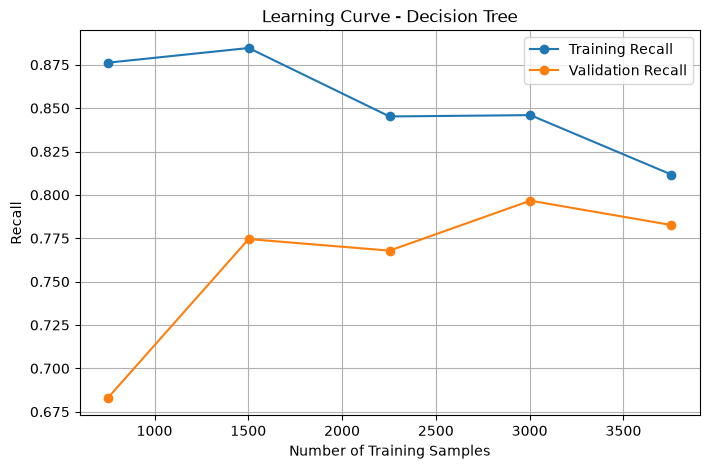

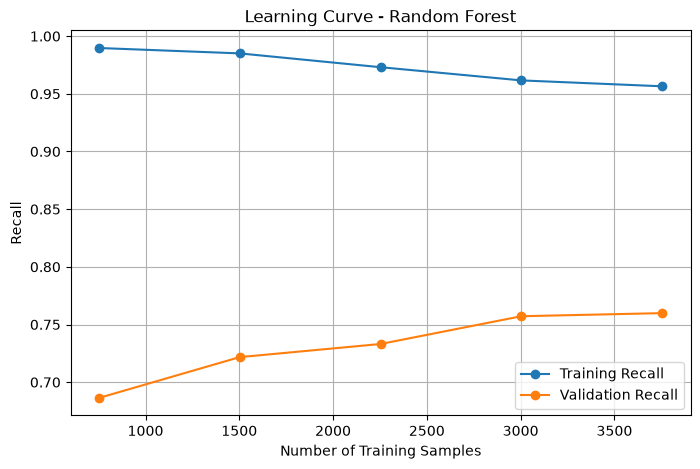

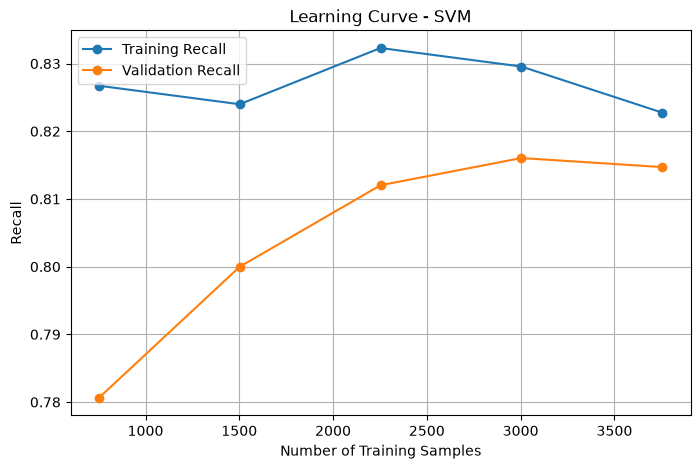

In [40]:

# Plot learning curves

for model_name, results in learning_curve_results.items():

    train_sizes = results["train_sizes"]
    train_mean = results["train_scores"].mean(axis=1)
    validation_mean = results["validation_scores"].mean(axis=1)

    plt.figure(figsize=(8, 5))

    plt.plot(train_sizes, train_mean, marker="o", label="Training Recall")
    plt.plot(train_sizes, validation_mean, marker="o", label="Validation Recall")

    plt.title(f"Learning Curve - {model_name}")
    plt.xlabel("Number of Training Samples")
    plt.ylabel("Recall")
    plt.legend()
    plt.grid(True)

    plt.show()



In [41]:
# Compare tuned models using cross-validation Recall

day3_comparison = pd.DataFrame({
    name: {
        "CV Recall": search.best_score_,
        "Best Parameters": str(search.best_params_)
    }
    for name, search in day3_searches.items()
}).T

print(day3_comparison)

              CV Recall                                    Best Parameters
Decision Tree  0.782617  {'classifier__max_depth': 5, 'classifier__min_...
Random Forest  0.759868  {'classifier__max_depth': 10, 'classifier__min...
SVM            0.814706  {'classifier__C': 1, 'classifier__gamma': 'auto'}


In [42]:
champion_name = max(
    day3_searches,
    key=lambda name: day3_searches[name].best_score_
)

champion_model = day3_best_models[champion_name]

print("Day 3 Champion:", champion_name)
print("Best CV Recall:",
      round(day3_searches[champion_name].best_score_, 4))

print("Best Parameters:",
      day3_searches[champion_name].best_params_)

Day 3 Champion: SVM
Best CV Recall: 0.8147
Best Parameters: {'classifier__C': 1, 'classifier__gamma': 'auto'}


In [43]:
import joblib
from pathlib import Path

model_path = Path("../models/churn_v3.joblib")

joblib.dump(champion_model, model_path)

print("Model saved:", model_path)


Model saved: ..\models\churn_v3.joblib


# Day 4

In [44]:

# DAY 4 - Feature Engineering

def engineer_features(data):

    data = data.copy()

    # 1. Group customer tenure
    data["tenure_group"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["0-12", "13-24", "25-48", "49-72"]
    ).astype("object")

    # 2. Average monthly spending
    data["avg_monthly_spend"] = (
        data["TotalCharges"] / (data["tenure"] + 1)
    )

    # 3. Contract flag
    data["is_month_to_month"] = (
        data["Contract"] == "Month-to-month"
    ).astype(int)

    # 4. Fiber internet flag
    data["has_fiber"] = (
        data["InternetService"] == "Fiber optic"
    ).astype(int)

    # 5. Electronic check flag
    data["is_electronic_check"] = (
        data["PaymentMethod"] == "Electronic check"
    ).astype(int)

    # 6. Online security flag
    data["has_online_security"] = (
        data["OnlineSecurity"] == "Yes"
    ).astype(int)

    return data


# Apply to training and testing data
X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)

print("Original features:", X_train.shape[1])
print("New features:", X_train_fe.shape[1])

print("\nNew feature columns:")
print(X_train_fe.columns[-6:].tolist())

print("\nSample engineered data:")
print(X_train_fe[
    [
        "tenure_group",
        "avg_monthly_spend",
        "is_month_to_month",
        "has_fiber",
        "is_electronic_check",
        "has_online_security"
    ]
].head())


Original features: 19
New features: 25

New feature columns:
['tenure_group', 'avg_monthly_spend', 'is_month_to_month', 'has_fiber', 'is_electronic_check', 'has_online_security']

Sample engineered data:
     tenure_group  avg_monthly_spend  is_month_to_month  has_fiber  \
3738        25-48          47.268056                  1          0   
3151        13-24          71.971875                  1          1   
4860        13-24          42.167857                  0          0   
3867        25-48          70.581481                  0          0   
3810         0-12          22.275000                  1          0   

      is_electronic_check  has_online_security  
3738                    1                    0  
3151                    0                    1  
4860                    0                    1  
3867                    0                    0  
3810                    1                    0  


In [45]:
from sklearn.feature_selection import SelectKBest, f_classif

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
num_cols_fe = X_train_fe.select_dtypes(
    include=["int64", "float64"]
).columns

cat_cols_fe = X_train_fe.select_dtypes(
    include=["object"]
).columns

# Numerical preprocessing
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor_day4 = ColumnTransformer([
    ("num", num_transformer, num_cols_fe),
    ("cat", cat_transformer, cat_cols_fe)
])

print("Numerical features:", len(num_cols_fe))
print("Categorical features:", len(cat_cols_fe))

Numerical features: 9
Categorical features: 16


In [47]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Model A - All features
rf_all = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Model B - Selected features
rf_selected = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("selector", SelectKBest(
        score_func=f_classif,
        k=20
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Evaluate both using cross-validation
all_scores = cross_val_score(
    rf_all, X_train_fe, y_train,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1
)

selected_scores = cross_val_score(
    rf_selected, X_train_fe, y_train,
    scoring="recall",
    cv=cv_strategy,
    n_jobs=-1
)

print("All Features Recall:", all_scores.mean())
print("Selected Features Recall:", selected_scores.mean())


All Features Recall: 0.6387916395039074
Selected Features Recall: 0.663581513763806


In [48]:
%pip install xgboost

  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/2f/3c/925394671f6a1668e2a71886de66e80be694eaf37f615cec74eefaf43107/xgboost-3.4.1-py3-none-win_amd64.whl.metadata
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB 262.6 kB/s eta 0:03:07
   ---------------------------------------- 0.1/48.9 MB 365.7 kB/s eta 0:02:14
   ---------------------------------------- 0.1/48.9 MB 711.9 kB/s eta 0:01:09
   ---------------------------------------- 0.3/48.9 MB 1.2 MB/s eta 0:00:42
   ---------------------------------------- 0.4/48.9 MB 1.3 MB/s eta 0:00:39
   ---------------------------------------- 0.5/48.9 MB 1.4 MB/s eta 0:00:35
    --------------------------------------- 0.6/48.9 MB 1.7 MB/s eta 0:00:29
    ------------------------------------


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:
from xgboost import XGBClassifier

In [50]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

In [51]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative:", negative)
print("Positive:", positive)
print("Scale pos weight:", scale_pos_weight)

Negative: 4139
Positive: 1495
Scale pos weight: 2.768561872909699


In [52]:
rf_model = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [53]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor_day4),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [54]:
rf_scores = cross_val_score(
    rf_model,
    X_train_fe,
    y_train,
    cv=cv_strategy,
    scoring="recall",
    n_jobs=-1
)

xgb_scores = cross_val_score(
    xgb_model,
    X_train_fe,
    y_train,
    cv=cv_strategy,
    scoring="recall",
    n_jobs=-1
)

print("Random Forest Recall:", rf_scores)
print("Random Forest Mean:", rf_scores.mean())

print("XGBoost Recall:", xgb_scores)
print("XGBoost Mean:", xgb_scores.mean())


Random Forest Recall: [0.70481928 0.71485944 0.71142285]
Random Forest Mean: 0.7103671868502736
XGBoost Recall: [0.79116466 0.7811245  0.78957916]
XGBoost Mean: 0.7872894383143798


In [55]:
# Train XGBoost on complete training data
xgb_model.fit(X_train_fe, y_train)

# Predictions
xgb_pred = xgb_model.predict(X_test_fe)

# Evaluate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

xgb_prob = xgb_model.predict_proba(X_test_fe)[:, 1]

xgb_test_results = {
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob)
}

print("Day 4 XGBoost Test Results")

for metric, value in xgb_test_results.items():
    print(f"{metric}: {value:.4f}")

Day 4 XGBoost Test Results
Accuracy: 0.7601
Precision: 0.5323
Recall: 0.7941
ROC-AUC: 0.8423


In [56]:
import joblib
from pathlib import Path

# Create models directory if required
Path("../models").mkdir(exist_ok=True)

# Save complete pipeline
joblib.dump(
    xgb_model,
    "../models/churn_v4.joblib"
)

print("Day 4 XGBoost model saved successfully!")

Day 4 XGBoost model saved successfully!
